# 03 Estratégia e demonstração do Tech Challenge

Vamos usar o baseline do notebook 02 para demonstrar **bloqueio de dados
inválidos, Data Drift e Concept Drift simulado**, gerar relatórios HTML
com Evidently e registrar a execução em logs JSON e no MLflow.

Ao final, consolidamos a estratégia de resposta, governança e entrega.
Execute o notebook 02 antes deste. Os dados e modelos são locais; nenhum
serviço externo é necessário. A documentação final e o vídeo ainda devem
ser entregues conforme o [enunciado](../docs/MLET%20-%20Tech%20Challenge%20-%20Fase%204.pdf).

## 1 Recuperar o modelo e as partições

`HomeCreditData` carrega as partições salvas no notebook 02 e valida
seus contratos e a ausência de IDs compartilhados.
`ModelPredictor` recupera do MLflow o modelo identificado pelo treinamento.
As execuções de monitoramento ficam vinculadas a essa origem.

In [1]:
import sys
from datetime import UTC, datetime
from pathlib import Path

from IPython.display import Markdown, display

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

from ml_prep_kit import (
    DataValidator,
    DriftMonitor,
    ExperimentTracker,
    HomeCreditData,
    ModelPredictor,
    VisualizationReporter,
)

/opt/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
processed_path = project_root / "data/processed"
preparation = HomeCreditData()
experiment = preparation.load_experiment(processed_path)
preparation.random_state = experiment["random_state"]
partitions = experiment["partitions"]
features = preparation.features
threshold = experiment["threshold"]
reference, production = partitions["treino"], partitions["producao"]
predictor = ModelPredictor.from_mlflow(
    experiment["model_uri"], tracking_uri=experiment["tracking_uri"]
)
validator = DataValidator()
reporter = VisualizationReporter()
display(validator.summarize({"referencia": reference, "producao": production}))
print(f"Treinamento de origem: {experiment['training_run_id']}")

,dataset,rows,columns,memory_mb
0,referencia,12000,12,3.202961
1,producao,4000,12,1.067339


Treinamento de origem: eb1cfe3dfa6f48d8b63fc6473f22d861


## 2 Contrato de dados e fronteira de bloqueio

O contrato se aplica **após as conversões determinísticas de idade e flags**
e antes de imputação, escala e predição. Ele exige esquema, IDs únicos,
idade válida, renda e crédito positivos, flags 0/1 e categorias preenchidas.
Anuidade ausente é permitida porque existe uma política explícita de imputação.

`TARGET` é opcional na inferência. Se estiver presente, deve conter 0/1.
Renda ou crédito podem mudar de distribuição sem violar uma regra de validade:
essa diferença será investigada pelo monitor estatístico.

In [3]:
contract = preparation.contract
reference = contract.validate(reference)
production = contract.validate(production)
_ = contract.validate(production.drop(columns=preparation.target))
print("Mesmo contrato do treinamento. TARGET é opcional na inferência.")

Mesmo contrato do treinamento. TARGET é opcional na inferência.


## 3 Cenários pareados de produção

Reutilizamos os mesmos 4.000 registros reservados para isolar o efeito das
intervenções. São **cenários pareados**, não novos clientes observados em
meses diferentes. Nenhum registro da produção foi usado para treinar.

| Cenário | Intervenção | Evidência esperada |
| --- | --- | --- |
| Controle | Nenhuma | Variação normal frente à referência |
| Dados inválidos | Renda nula, idade negativa e ID duplicado | Bloqueio antes do modelo |
| Data Drift | Renda multiplicada por 0,70 e crédito por 1,40 | Mudança detectada nas duas features |
| Concept Drift | Parte dos desfechos muda em um segmento de renda | Mudança de desempenho com entradas idênticas ao controle |

No Concept Drift, simulamos um choque não refletido na renda declarada:
metade, em média, dos casos originalmente negativos com renda a partir do
terceiro quartil do **treino** passa a ter dificuldade de pagamento.
A regra e a seed tornam a intervenção verificável. Os novos rótulos são
sintéticos e não representam desfechos reais.

No Data Drift, os rótulos são mantidos apenas para uma comparação didática;
alterar uma feature não revela o desfecho contrafactual verdadeiro.

In [4]:
scenarios, concept_metadata = preparation.scenarios(production, reference)
display(validator.compare_targets(scenarios, preparation.target))
display(concept_metadata)

,dataset,target,count,percent
0,dados_invalidos,0,19,95.000
1,dados_invalidos,1,1,5.000
2,controle,0,3677,91.925
3,controle,1,323,8.075
4,data_drift,0,3677,91.925
5,data_drift,1,323,8.075
6,concept_drift,0,3130,78.250
7,concept_drift,1,870,21.750


{'cutoff': 202500.0, 'changed_labels': 547}

## 4 Logs e rastreamento local

Cada cenário será executado explicitamente no laço do notebook,
usando `DriftMonitor` e `ExperimentTracker`. O framework valida,
calcula métricas e escreve os relatórios; o notebook organiza as chamadas.

Os logs são JSON, com status, volume, duração e alertas. As execuções do
MLflow apontam para o treinamento de origem. Ainda falta complementar
a saúde da infraestrutura e a observabilidade das demais etapas.

In [5]:
tracking_path = processed_path / "monitoring"
execution_id = datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
execution_path = tracking_path / execution_id
tracker = ExperimentTracker(
    "tech-challenge-4-fintech",
    tracking_uri=experiment["tracking_uri"],
    artifact_location=(tracking_path / "mlartifacts").as_uri(),
)

## 5 Configuração da detecção estatística

O Evidently compara cada cenário com as dez features do treino. Usamos
**Kolmogorov-Smirnov**, com valor-p menor que `0,01`, para as numéricas;
**PSI**, com valor a partir de `0,20`, para categóricas e flags.
O alerta global considera ao menos 20% das features em drift.

Os limiares são parâmetros demonstrativos, definidos antes da comparação.
Tamanho amostral e múltiplos testes afetam falsos alertas; o controle ajuda
a contextualizá-los e não há garantia de zero alertas em amostras independentes.
Os relatórios exibem também as distribuições para interpretar a relevância prática.

Alvo e ID são excluídos da análise de Data Drift. Para Concept Drift,
comparamos métricas com rótulos e a intervenção conhecida; mudança de
distribuição das entradas não é uma prova da mudança de conceito.

In [6]:
monitor = DriftMonitor(
    output_dir=execution_path,
    numeric_columns=preparation.numeric_features,
    categorical_columns=preparation.categorical_features + preparation.binary_features,
    ks_threshold=0.01,
    psi_threshold=0.20,
    drift_share=0.20,
    auc_drop_threshold=0.05,
)

## 6 Executar, bloquear e registrar os cenários

Cada chamada a `DriftMonitor.evaluate_batch` valida o lote antes da
predição, gera os relatórios e devolve as métricas para o MLflow.
Os testes verificam que o lote inválido não chega ao modelo.

A queda de ROC AUC é comparada ao controle e serve como sinal de investigação.
Sem rótulos, essa comparação fica indisponível; Data Drift continua mensurável.

In [7]:
results = {}
control_auc = None
with tracker.run(
    execution_id,
    parameters={
        **monitor.parameters,
        **concept_metadata,
        "threshold": threshold,
        "seed": preparation.random_state,
        "concept_labels": "synthetic",
    },
    tags={
        "training_run_id": experiment["training_run_id"],
        "model_uri": experiment["model_uri"],
    },
) as monitoring_run:
    for name, batch in scenarios.items():
        with tracker.run(name, nested=True):
            result = monitor.evaluate_batch(
                name,
                batch,
                reference,
                predictor,
                contract,
                target=preparation.target,
                threshold=threshold,
                control_auc=control_auc,
            )
            tracker.log(
                metrics=result["metrics"],
                tags={"status": result["status"]},
                artifacts=result["artifacts"],
            )
            results[name] = result
            if name == "controle":
                control_auc = result["metrics"]["roc_auc"]
    summary = monitor.summarize(results, execution_path / "summary.json")
    tracker.log(
        artifacts=[execution_path / "summary.json", execution_path / "pipeline.jsonl"]
    )
display(results["dados_invalidos"]["quality_failures"])
display(
    summary[
        [
            "quality_passed",
            "drifted_features",
            "roc_auc",
            "average_precision",
            "recall",
            "f1",
            "auc_drop",
            "drift_alert",
            "performance_alert",
            "duration_seconds",
        ]
    ]
)

2026/10/10 15:22:22 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/10 15:22:22 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git branch is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/10 15:22:22 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git repository URL is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



,column,check,violations
0,AGE_YEARS,"in_range(18, 100)",1
1,AMT_INCOME_TOTAL,not_nullable,1
2,SK_ID_CURR,field_uniqueness,2


,quality_passed,drifted_features,roc_auc,average_precision,recall,f1,auc_drop,drift_alert,performance_alert,duration_seconds
dados_invalidos,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.011868
controle,1.0,0.0,0.601531,0.111315,0.603715,0.189781,NaN,0.0,NaN,0.383068
data_drift,1.0,2.0,0.602180,0.111514,0.569659,0.189789,-0.000649,1.0,0.0,0.338284
concept_drift,1.0,0.0,0.456222,0.197527,0.412644,0.275942,0.145309,0.0,1.0,0.342126


## 7 Interpretar as evidências

Os scores de controle e Concept Drift são idênticos porque as entradas não
mudaram. Se o desempenho cai com os novos rótulos, o monitor de features
sozinho não consegue explicar essa mudança. A interpretação depende da
intervenção conhecida e, na operação real, da obtenção dos desfechos.

Data Drift pode existir com ou sem queda de desempenho. Os testes estatísticos
identificam mudanças; a severidade exige contexto e avaliação dos resultados.

A taxa de positivos também muda no Concept Drift. Average Precision e F1 podem
aumentar mesmo quando a ordenação piora; compare essas métricas com a prevalência
do alvo. O alerta demonstrado usa a queda de ROC AUC, e não exige queda simultânea
de todas as métricas.

Os mesmos relatórios completos do `ModelEvaluator` são aplicados a cada cenário,
incluindo contagens, métricas por classe e calibração. Os JSONs `classification_*`
ficam anexados às respectivas execuções do MLflow.


,feature,method,score,threshold,drift
0,AGE_YEARS,ks,4.350824e-01,0.01,False
1,AMT_INCOME_TOTAL,ks,0.000000e+00,0.01,True
2,AMT_CREDIT,ks,6.947000e-102,0.01,True
3,AMT_ANNUITY,ks,4.057791e-01,0.01,False
4,CNT_CHILDREN,ks,5.939094e-01,0.01,False
5,NAME_INCOME_TYPE,psi,9.222419e-03,0.20,False
6,NAME_EDUCATION_TYPE,psi,9.980977e-04,0.20,False
7,NAME_HOUSING_TYPE,psi,9.286781e-04,0.20,False
8,FLAG_OWN_CAR,psi,2.911016e-04,0.20,False
9,FLAG_OWN_REALTY,psi,1.402804e-03,0.20,False


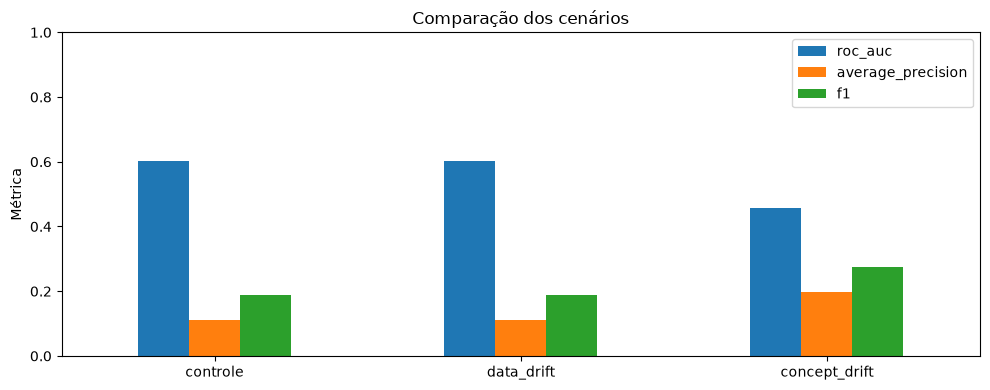

[Abrir relatório Evidently de controle](../data/processed/monitoring/20261010T152222109266Z/controle.html)

,class,precision,recall,f1,support
0,0,0.943563,0.581996,0.719933,3677
1,1,0.112587,0.603715,0.189781,323


[Abrir relatório Evidently de data_drift](../data/processed/monitoring/20261010T152222109266Z/data_drift.html)

,class,precision,recall,f1,support
0,0,0.941695,0.610552,0.740802,3677
1,1,0.113861,0.569659,0.189789,323


[Abrir relatório Evidently de concept_drift](../data/processed/monitoring/20261010T152222109266Z/concept_drift.html)

,class,precision,recall,f1,support
0,0,0.774691,0.561342,0.650982,3130
1,1,0.207275,0.412644,0.275942,870


Execução MLflow: e63fc00e928a4df1b10556854b8ef8a5


,precision,recall,specificity,false_positive_rate,false_negative_rate,balanced_accuracy,matthews_correlation,brier_score,log_loss,true_positives,false_positives,false_negatives,true_negatives
dados_invalidos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
controle,0.1126,0.6037,0.5820,0.4180,0.3963,0.5929,0.1021,0.2389,0.6698,195.0,1537.0,128.0,2140.0
data_drift,0.1139,0.5697,0.6106,0.3894,0.4303,0.5901,0.1001,0.2314,0.6538,184.0,1432.0,139.0,2245.0
concept_drift,0.2073,0.4126,0.5613,0.4387,0.5874,0.4870,-0.0217,0.2593,0.7141,359.0,1373.0,511.0,1757.0


In [8]:
display(results["data_drift"]["drift_table"])
_ = reporter.plot_metrics(
    summary.loc[["controle", "data_drift", "concept_drift"]],
    ["roc_auc", "average_precision", "f1"],
)
for name in ["controle", "data_drift", "concept_drift"]:
    relative_path = (execution_path / f"{name}.html").relative_to(project_root)
    display(Markdown(f"[Abrir relatório Evidently de {name}](../{relative_path})"))
    display(results[name]["evaluation"]["by_class"])
print(f"Execução MLflow: {monitoring_run.info.run_id}")
display(
    summary[
        [
            "precision",
            "recall",
            "specificity",
            "false_positive_rate",
            "false_negative_rate",
            "balanced_accuracy",
            "matthews_correlation",
            "brier_score",
            "log_loss",
            "true_positives",
            "false_positives",
            "false_negatives",
            "true_negatives",
        ]
    ].round(4)
)

## 8 Estratégia de resposta operacional

| Sinal | Ação proposta | Evidência para encerrar a investigação |
| --- | --- | --- |
| Contrato inválido | Bloquear lote e solicitar correção à origem | Novo lote aprovado e causa registrada |
| Drift em renda ou crédito | Conferir coleta, unidades e mudança de perfil | Explicação da alteração e análise do impacto |
| Queda de desempenho | Investigar segmentos e novos desfechos | Comparação do baseline e de alternativas em avaliação independente |
| Falha de geração de relatório | Registrar falha operacional e reexecutar após correção | Relatório íntegro vinculado à execução |

Não retreinar nem promover automaticamente um modelo apenas porque existe
drift. Primeiro distinguir problema de coleta, mudança válida de população
e mudança na relação com o alvo. Definir responsável e prazo de análise na
documentação de operação. Medir latência por etapa e recursos da infraestrutura
é o próximo incremento de observabilidade.

Para abrir a interface do MLflow no mesmo ambiente Docker da demonstração,
execute na raiz do projeto:

```bash
docker compose --file docker/docker-compose.yml run --rm -p 5000:5000 notebook \
  mlflow ui --host 0.0.0.0 --port 5000 \
  --backend-store-uri sqlite:////app/data/processed/monitoring/mlflow.db
```

Acesse `http://localhost:5000`. Os artefatos locais usam os caminhos do
ambiente que os gerou; use a mesma montagem `/app` ao abrir execuções feitas
no container. Em execução local, use a URI do banco exibida pela configuração
deste notebook e mantenha o mesmo diretório do projeto.

## 9 Governança e causalidade para a entrega

O README deve consolidar decisões específicas deste experimento:

- Finalidade acadêmica, origem, condições de uso e limites dos dados.
- Tratamento do identificador como dado de rastreabilidade, sem incluí-lo no modelo.
- Avaliação de idade, escolaridade e demais possíveis proxies de discriminação.
- Plano de acesso e retenção para CSV, modelo, partições salvas, logs e relatórios.
- Discussão fundamentada da base legal para o cenário de crédito e das diferenças
  entre um protótipo acadêmico e uma operação real, com fontes oficiais.
- Identificação dos rótulos sintéticos e dos limites de inferência causal.
- Procedimentos de revisão, resposta a incidentes e eventual atualização do modelo.

A hipótese de Data Drift é uma alteração simulada do perfil de renda e crédito.
A hipótese de Concept Drift é um choque de pagamento em um segmento, mantendo
as entradas observadas. Nenhum resultado comprova que esses eventos ocorreram
na população original. Não publicar dados individuais ou o arquivo com as partições
como evidência pública; preferir métricas agregadas e relatórios revisados.

## 10 O que foi demonstrado e o que falta entregar

| Requisito | Situação após executar os três notebooks |
| --- | --- |
| Conhecer a base e validar o recorte | Notebook 01 |
| Limpar, normalizar e treinar baseline | Notebook 02 |
| Contrato Pandera e bloqueio antes do modelo | Notebook 03 |
| Simular alteração de duas features | Notebook 03 |
| Evidently e relatórios HTML de drift | Notebook 03 |
| Concept Drift com rótulos sintéticos | Notebook 03 |
| Logs e rastreamento MLflow dos cenários | Notebook 03 |
| Saúde da infraestrutura e métricas por etapa | Completar antes da entrega final |
| README de arquitetura, governança e causalidade | Consolidar antes da entrega final |
| Componentes reutilizáveis e testes | Lógica centralizada e testada no ml_prep_kit; falta consolidar comando de entrega |
| Vídeo STAR de até cinco minutos | Gravar a demonstração final |

O vídeo deve mostrar: risco de degradação silenciosa; requisitos; lote
rejeitado, alterações e relatórios; resultados e resposta proposta.
Para reprodução, executar 01, 02 e 03 nessa ordem, sempre do início ao fim.
O checklist local de acompanhamento complementa a organização do trabalho;
as evidências e instruções de avaliação precisam estar na documentação entregue.
